# Exploratory Data Analysis (EDA) on Superstore Retail Sales
**Objective:** Data wrangling, missing-value profiling, and analysis of commercial sales distributions.

**Focus areas:** Customer purchase volume, monthly seasonality, category-wise revenue, discount sensitivity

**Dataset:** `superstore_sales.csv` (US Superstore orders, 2015-2018)

**Tools:** Python (Pandas, Matplotlib, Seaborn)

## 1. Setup and Data Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titleweight'] = 'bold'
pd.options.display.float_format = '{:,.2f}'.format

In [2]:
import os
# Looks for the CSV in the repo's data/ folder first, then next to the notebook (e.g. when using Colab)
FILE = next(p for p in ['../data/superstore_sales.csv', 'data/superstore_sales.csv', 'superstore_sales.csv'] if os.path.exists(p))
raw = pd.read_csv(FILE)
print('Raw shape:', raw.shape)
raw.head()

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Postal Code,"9,983.00","55,245.23","32,038.72","1,040.00","23,223.00","57,103.00","90,008.00","99,301.00"
Sales,"9,994.00",229.86,623.25,0.44,17.28,54.49,209.94,"22,638.48"
Quantity,"9,994.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,"9,994.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"9,994.00",28.66,234.26,"-6,599.98",1.73,8.67,29.36,"8,399.98"


**Observation:** The raw file has 10,800 rows, but only about 9,994 are real orders. In the remaining rows `Sales`, `Order Date` and most other columns are empty. The next steps find out why.

## 2. Data Cleaning and Wrangling

### 2.1 Missing value profiling

In [5]:
miss = raw.isna().sum().to_frame('missing_count')
miss['missing_pct'] = miss['missing_count'] / len(raw) * 100
miss[miss.missing_count > 0].sort_values('missing_count', ascending=False)

,missing_count,missing_pct
Postal Code,817,7.56
Ship Date,806,7.46
Order Date,806,7.46
Ship Mode,806,7.46
Customer ID,806,7.46
Segment,806,7.46
Customer Name,806,7.46
Country,806,7.46
City,806,7.46
State,806,7.46


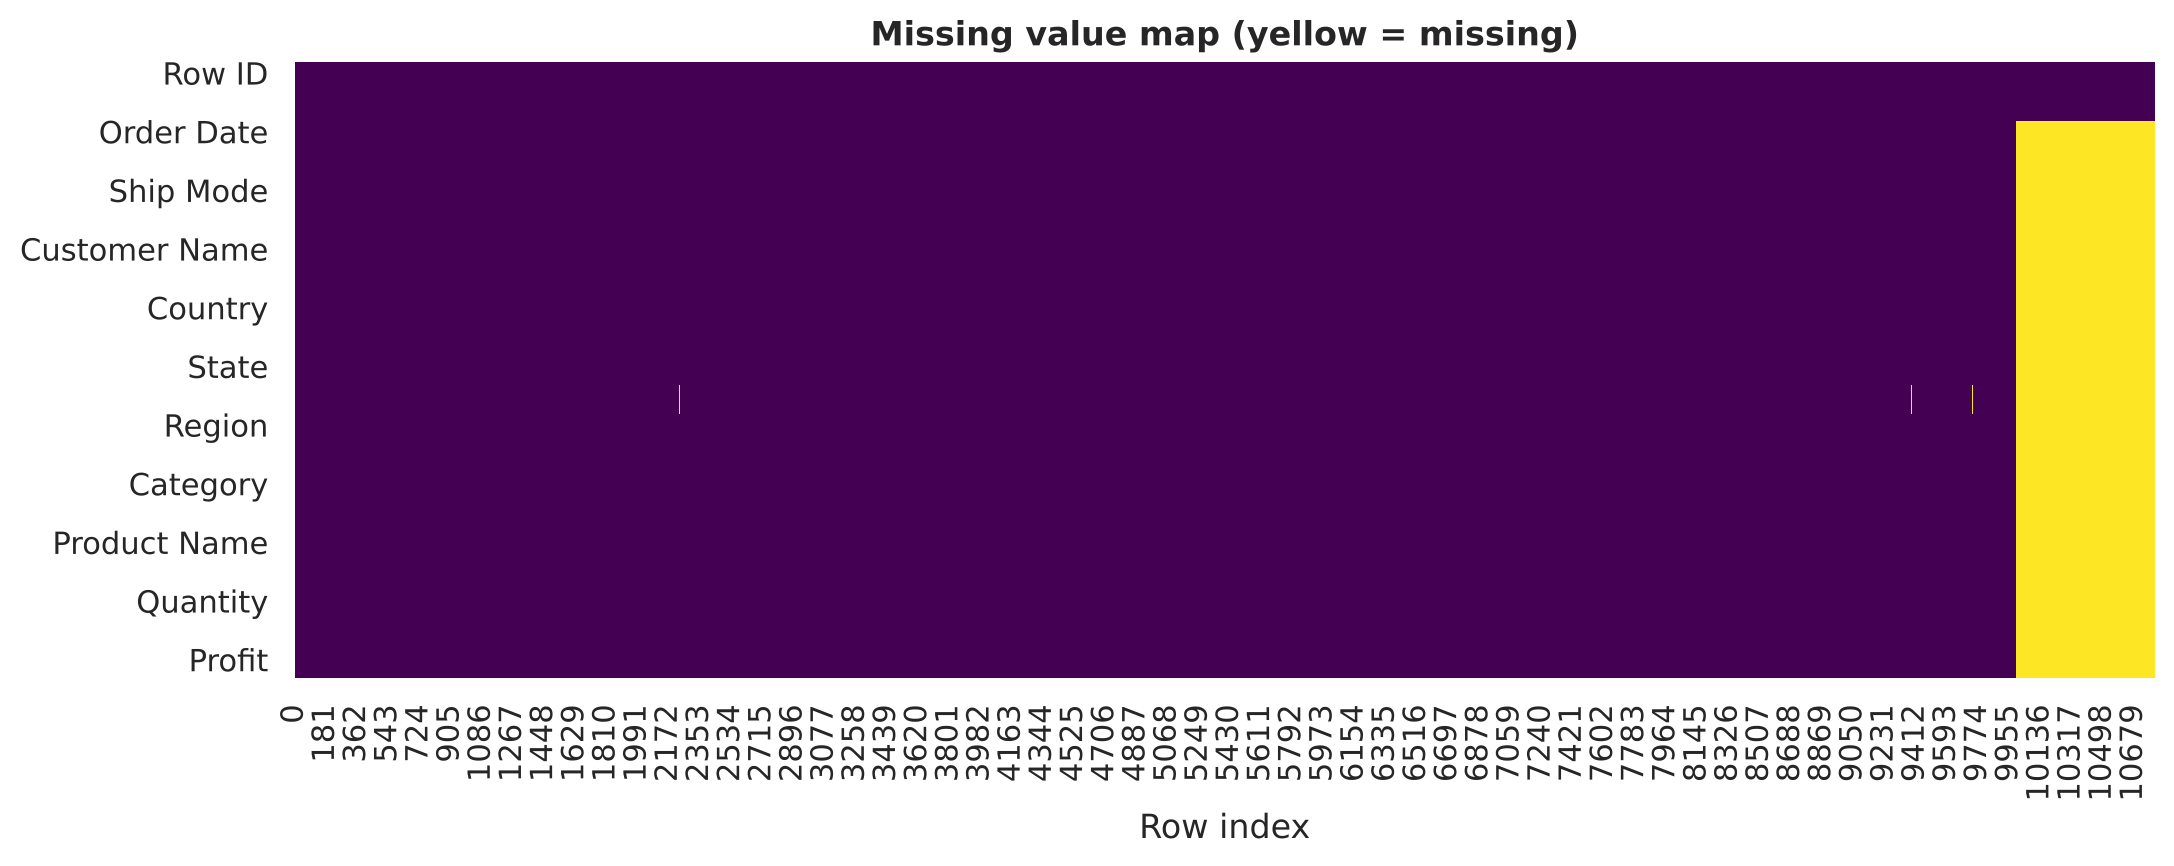

In [6]:
plt.figure(figsize=(12, 4))
sns.heatmap(raw.isna().T, cbar=False, cmap='viridis')
plt.title('Missing value map (yellow = missing)')
plt.xlabel('Row index'); plt.show()

The heatmap shows that almost every column is empty after row 9,994. Let's check what `Row ID` contains in that part of the file.

In [7]:
raw.iloc[9990:9998, :6]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID
9990,9991,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060
9991,9992,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060
9992,9993,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060
9993,9994,CA-2018-119914,5/4/2018,5/9/2018,Second Class,CC-12220
9994,Person,Region,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN


In [8]:
print(raw['Row ID'].iloc[9994:].value_counts().head(8))

Row ID
Yes                  800
Person                 1
Anna Andreadi          1
Chuck Magee            1
Kelly Williams         1
Cassandra Brandow      1
Returned               1
Name: count, dtype: int64


**Cause:** Two unrelated lookup tables (regional manager names and a list of `Returned = Yes` orders) were appended to the end of the file. They are not order data, so they are **dropped**. Filling them makes no sense because Sales and Profit cannot be invented.

### 2.2 Drop junk rows and handle real nulls

In [9]:
df = raw[raw['Sales'].notna()].copy()
print(f'Dropped junk rows : {len(raw) - len(df)}')
print(f'Clean row count   : {len(df)}')
df.isna().sum()[df.isna().sum() > 0]

Dropped junk rows : 806
Clean row count   : 9994


Postal Code    11
dtype: int64

In [10]:
# Remaining missing values: Postal Code (only Burlington, Vermont)
print(df[df['Postal Code'].isna()][['City', 'State']].drop_duplicates())
print('Other Burlington, VT postal code:',
      df[(df.City == 'Burlington') & (df.State == 'Vermont')]['Postal Code'].dropna().unique())

            City    State
2234  Burlington  Vermont
Other Burlington, VT postal code: []


In [11]:
# The ZIP code for Burlington, Vermont is 05401 (stored as numeric 5401), so we fill it in.
df['Postal Code'] = df['Postal Code'].fillna(5401).astype(int)
print('Remaining nulls:', df.isna().sum().sum())

Remaining nulls: 0


**Decision:** Postal Code was missing for only one city, so instead of dropping those rows we filled in the correct ZIP code. ZIP is not used in the analysis, but a complete dataset is cleaner.

### 2.3 Duplicate check

In [12]:
dup_cols = [c for c in df.columns if c != 'Row ID']
print('Duplicate Row ID :', df['Row ID'].duplicated().sum())
print('Duplicate rows   :', df.duplicated(subset=dup_cols).sum())
df[df.duplicated(subset=dup_cols, keep=False)][['Row ID', 'Order ID', 'Product Name', 'Sales', 'Quantity']]

Duplicate Row ID : 0
Duplicate rows   : 1


,Row ID,Order ID,Product Name,Sales,Quantity
3405,3406,US-2015-150119,Global Leather Highback Executive Chair with P...,281.37,2.00
3406,3407,US-2015-150119,Global Leather Highback Executive Chair with P...,281.37,2.00


In [13]:
df = df.drop_duplicates(subset=dup_cols).reset_index(drop=True)
print('Rows after dedup:', len(df))

Rows after dedup: 9993


Rows with the same order, product and quantity appearing twice were treated as duplicates (ignoring `Row ID`), and one copy was kept.

### 2.4 Fix data types and create date features

In [14]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date']  = pd.to_datetime(df['Ship Date'],  format='%m/%d/%Y')
df['Row ID']     = df['Row ID'].astype(int)
df['Quantity']   = df['Quantity'].astype(int)

df['Year']       = df['Order Date'].dt.year
df['Month']      = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.strftime('%b')
df['Year-Month'] = df['Order Date'].dt.to_period('M')
df['Ship Days']  = (df['Ship Date'] - df['Order Date']).dt.days
df['Profit Margin %'] = df['Profit'] / df['Sales'] * 100

print(df['Order Date'].min().date(), '->', df['Order Date'].max().date())
df.dtypes

2015-01-03 -> 2018-12-30


Row ID                      int64
Order ID                      str
Order Date         datetime64[us]
Ship Date          datetime64[us]
Ship Mode                     str
Customer ID                   str
Customer Name                 str
Segment                       str
Country                       str
City                          str
State                         str
Postal Code                 int64
Region                        str
Product ID                    str
Category                      str
Sub-Category                  str
Product Name                  str
Sales                     float64
Quantity                    int64
Discount                  float64
Profit                    float64
Year                        int32
Month                       int32
Month Name                    str
Year-Month              period[M]
Ship Days                   int64
Profit Margin %           float64
dtype: object

### 2.5 Quick outlier check

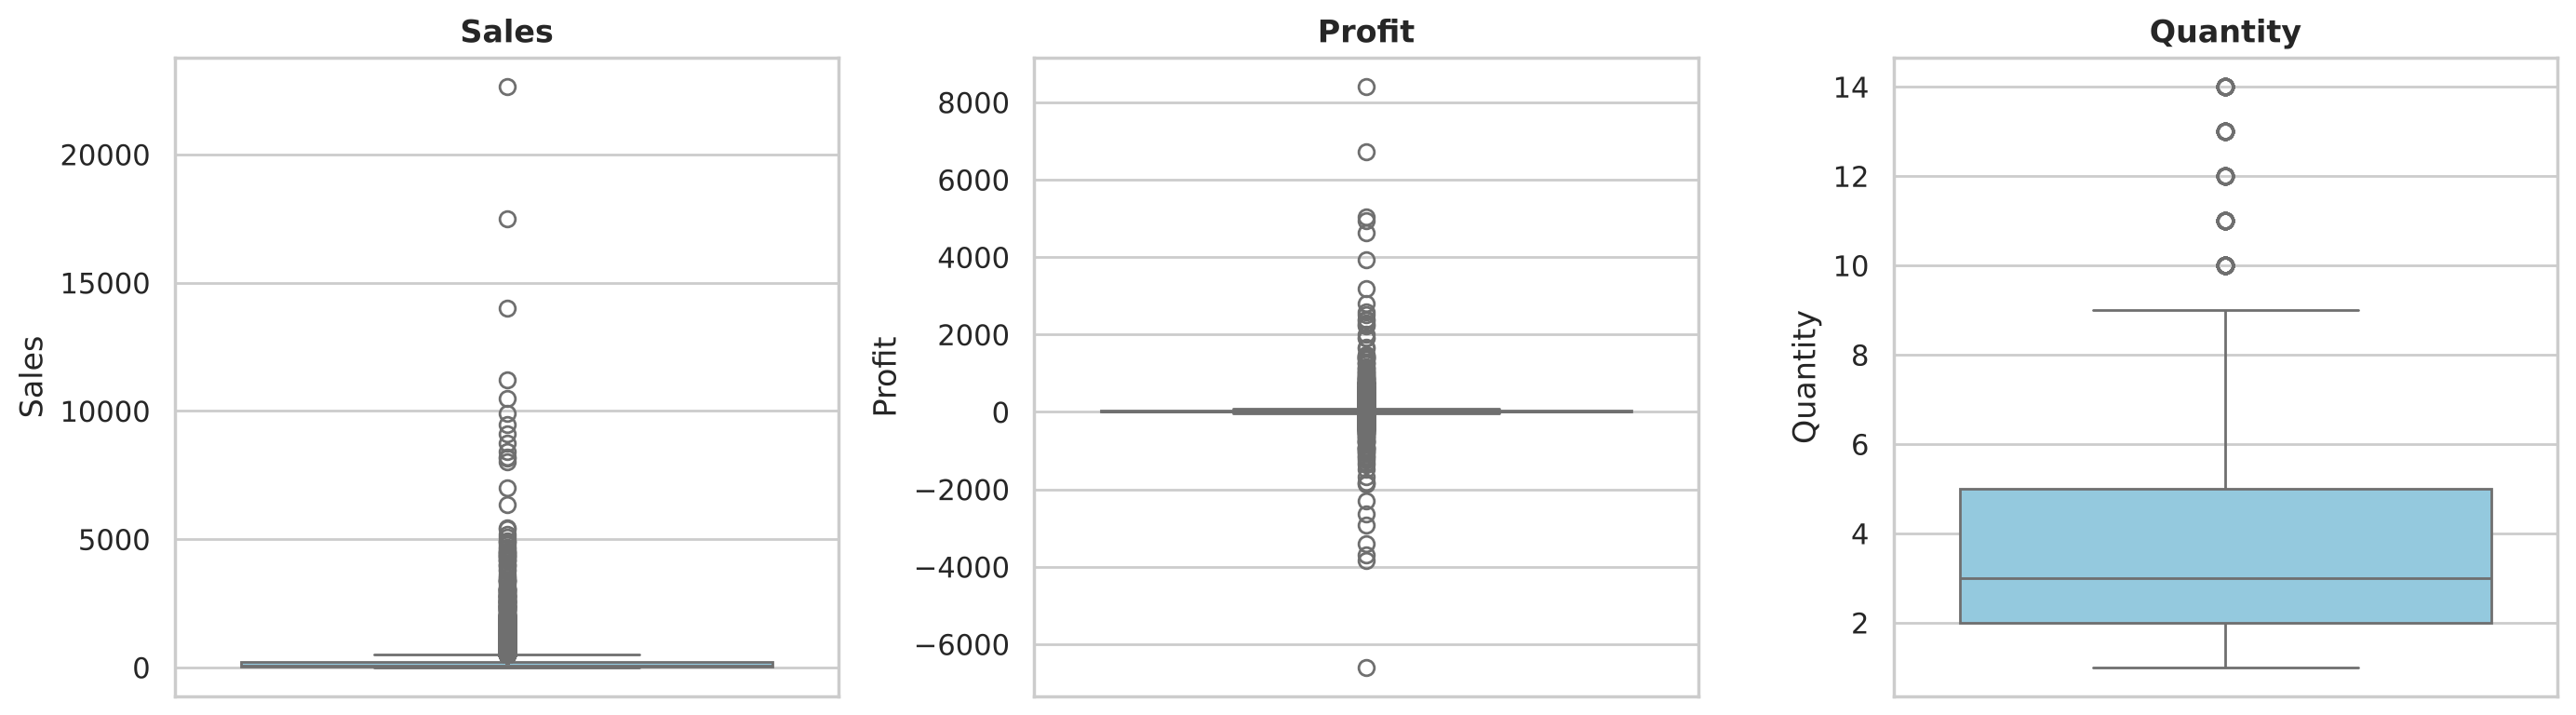

,count,mean,std,min,25%,50%,75%,max
Sales,"9,993.00",229.85,623.28,0.44,17.28,54.48,209.94,"22,638.48"
Profit,"9,993.00",28.66,234.27,"-6,599.98",1.73,8.67,29.36,"8,399.98"


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col in zip(ax, ['Sales', 'Profit', 'Quantity']):
    sns.boxplot(y=df[col], ax=a, color='skyblue'); a.set_title(col)
plt.tight_layout(); plt.show()
df[['Sales', 'Profit']].describe().T

Sales and Profit contain some very large values (for example big Technology/Copier orders). These are genuine large sales, not data errors, so they were **kept**. The large negative Profit values come from heavy discounts, which Section 7 examines.

In [16]:
print(f'Clean dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Total Sales : ${df.Sales.sum():,.0f}')
print(f'Total Profit: ${df.Profit.sum():,.0f}')
print(f'Overall margin: {df.Profit.sum()/df.Sales.sum()*100:.1f}%')

Clean dataset: 9,993 rows x 27 columns
Total Sales : $2,296,919
Total Profit: $286,409
Overall margin: 12.5%


## 3. Aggregation: Category, Region, Segment

In [17]:
def summarize(by):
    g = df.groupby(by).agg(Sales=('Sales', 'sum'), Profit=('Profit', 'sum'),
                           Orders=('Order ID', 'nunique'), Quantity=('Quantity', 'sum'))
    g['Margin %'] = g['Profit'] / g['Sales'] * 100
    return g.sort_values('Sales', ascending=False)

cat_sum = summarize('Category'); cat_sum

,Sales,Profit,Orders,Quantity,Margin %
Category,,,,,
Technology,"836,154.03","145,454.95",1544,6939,17.40
Furniture,"741,718.42","18,463.33",1764,8026,2.49
Office Supplies,"719,047.03","122,490.80",3742,22906,17.04


In [18]:
reg_sum = summarize('Region'); reg_sum

,Sales,Profit,Orders,Quantity,Margin %
Region,,,,,
West,"725,457.82","108,418.45",1611,12266,14.94
East,"678,499.87","91,534.84",1401,10616,13.49
Central,"501,239.89","39,706.36",1175,8780,7.92
South,"391,721.91","46,749.43",822,6209,11.93


In [19]:
seg_sum = summarize('Segment'); seg_sum

,Sales,Profit,Orders,Quantity,Margin %
Segment,,,,,
Consumer,"1,161,401.34","134,119.21",2586,19521,11.55
Corporate,"706,146.37","91,979.13",1514,11608,13.03
Home Office,"429,371.78","60,310.74",909,6742,14.05


In [20]:
pivot_cr = df.pivot_table(index='Category', columns='Region', values=['Sales', 'Profit'], aggfunc='sum', margins=True)
pivot_cr

Profit                                            \
Region            Central      East     South       West        All   
Category                                                              
Furniture       -2,871.05  3,058.22  6,771.21  11,504.95  18,463.33   
Office Supplies  8,879.98 41,014.58 19,986.39  52,609.85 122,490.80   
Technology      33,697.43 47,462.04 19,991.83  44,303.65 145,454.95   
All             39,706.36 91,534.84 46,749.43 108,418.45 286,409.08   

                     Sales                                                
Region             Central       East      South       West          All  
Category                                                                  
Furniture       163,797.16 208,009.83 117,298.68 252,612.74   741,718.42  
Office Supplies 167,026.42 205,516.05 125,651.31 220,853.25   719,047.03  
Technology      170,416.31 264,973.98 148,771.91 251,991.83   836,154.03  
All             501,239.89 678,499.87 391,721.91 725,457.82 2,296,919.49

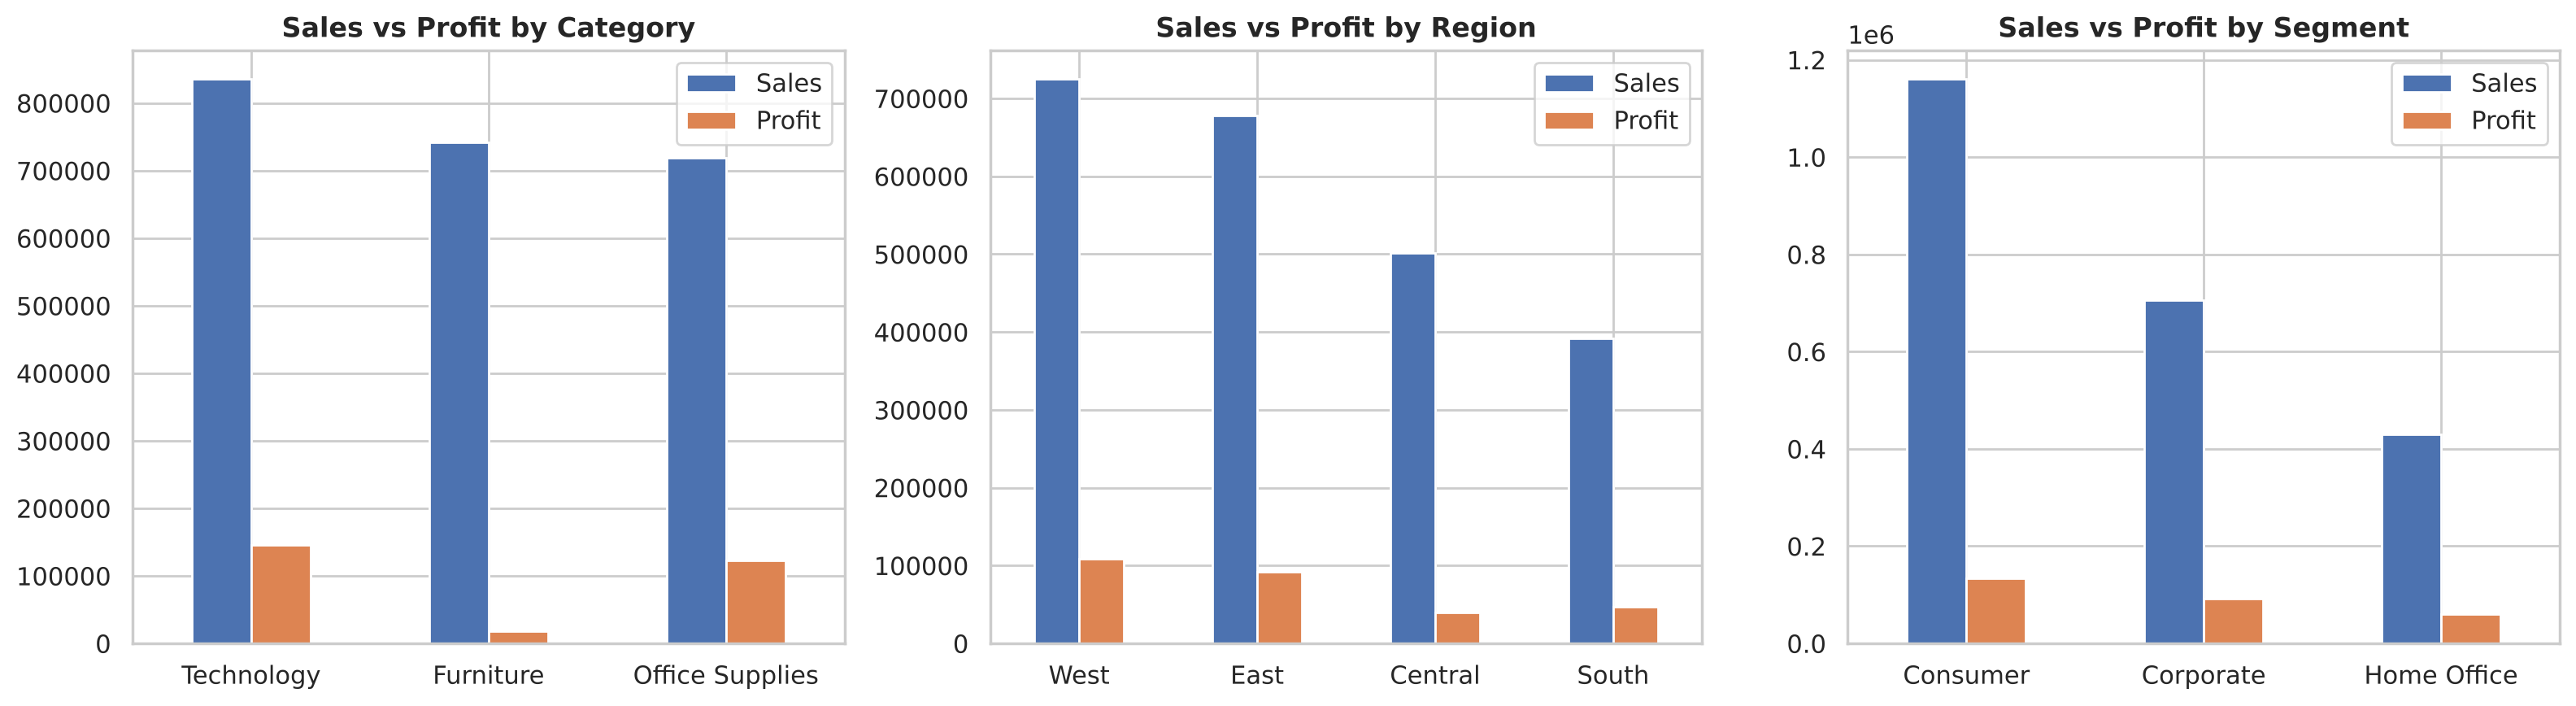

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (name, t) in zip(ax, [('Category', cat_sum), ('Region', reg_sum), ('Segment', seg_sum)]):
    t[['Sales', 'Profit']].plot(kind='bar', ax=a, rot=0)
    a.set_title(f'Sales vs Profit by {name}'); a.set_xlabel('')
plt.tight_layout(); plt.show()

## 4. Customer Purchase Volume

In [22]:
cust = df.groupby(['Customer ID', 'Customer Name', 'Segment']).agg(
    Orders=('Order ID', 'nunique'), Sales=('Sales', 'sum'), Profit=('Profit', 'sum')).reset_index()
cust['Avg Order Value'] = cust['Sales'] / cust['Orders']
print('Total customers:', len(cust))
cust['Orders'].describe()

Total customers: 793


count   793.00
mean      6.32
std       2.55
min       1.00
25%       5.00
50%       6.00
75%       8.00
max      17.00
Name: Orders, dtype: float64

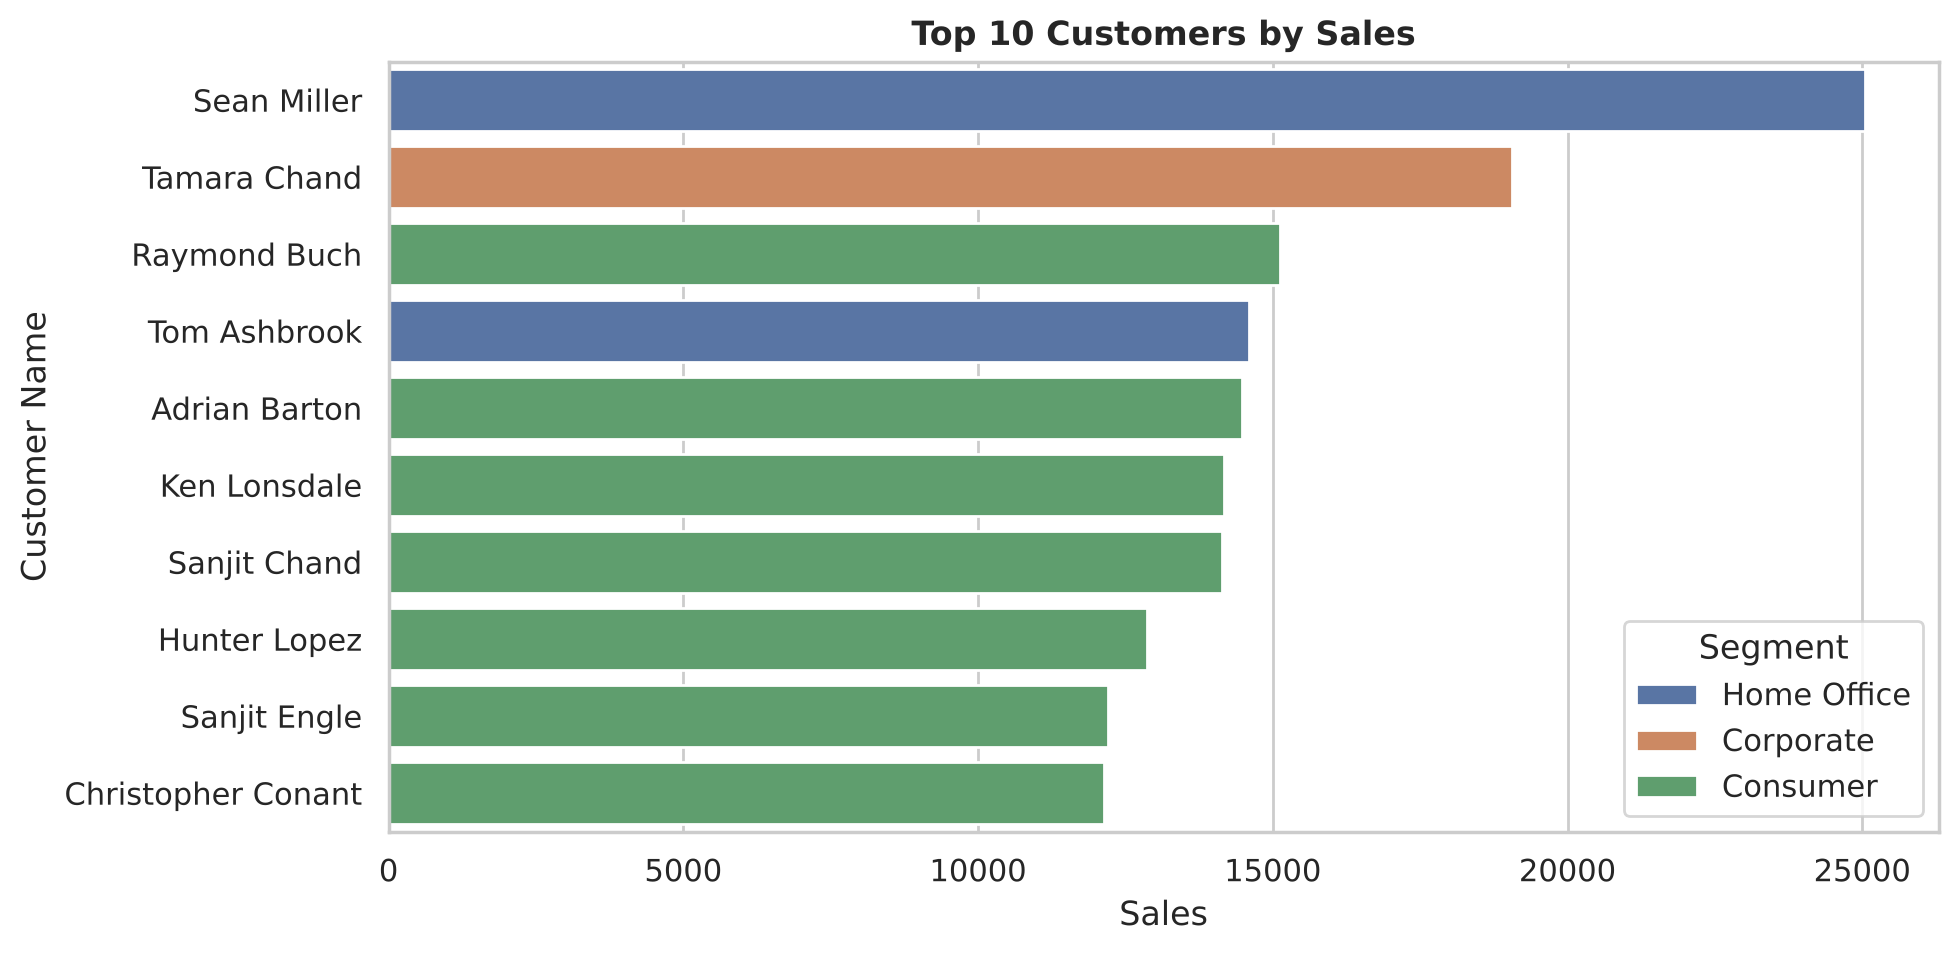

,Customer ID,Customer Name,Segment,Orders,Sales,Profit,Avg Order Value
700,SM-20320,Sean Miller,Home Office,5,"25,043.05","-1,980.74","5,008.61"
741,TC-20980,Tamara Chand,Corporate,5,"19,052.22","8,981.32","3,810.44"
621,RB-19360,Raymond Buch,Consumer,6,"15,117.34","6,976.10","2,519.56"
730,TA-21385,Tom Ashbrook,Home Office,4,"14,595.62","4,703.79","3,648.91"
6,AB-10105,Adrian Barton,Consumer,10,"14,473.57","5,444.81","1,447.36"
434,KL-16645,Ken Lonsdale,Consumer,12,"14,175.23",806.86,"1,181.27"
669,SC-20095,Sanjit Chand,Consumer,9,"14,142.33","5,757.41","1,571.37"
327,HL-15040,Hunter Lopez,Consumer,6,"12,873.30","5,622.43","2,145.55"
683,SE-20110,Sanjit Engle,Consumer,11,"12,209.44","2,650.68","1,109.95"
131,CC-12370,Christopher Conant,Consumer,5,"12,129.07","2,177.05","2,425.81"


In [23]:
top10 = cust.sort_values('Sales', ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(data=top10, y='Customer Name', x='Sales', hue='Segment', dodge=False)
plt.title('Top 10 Customers by Sales'); plt.show()
top10

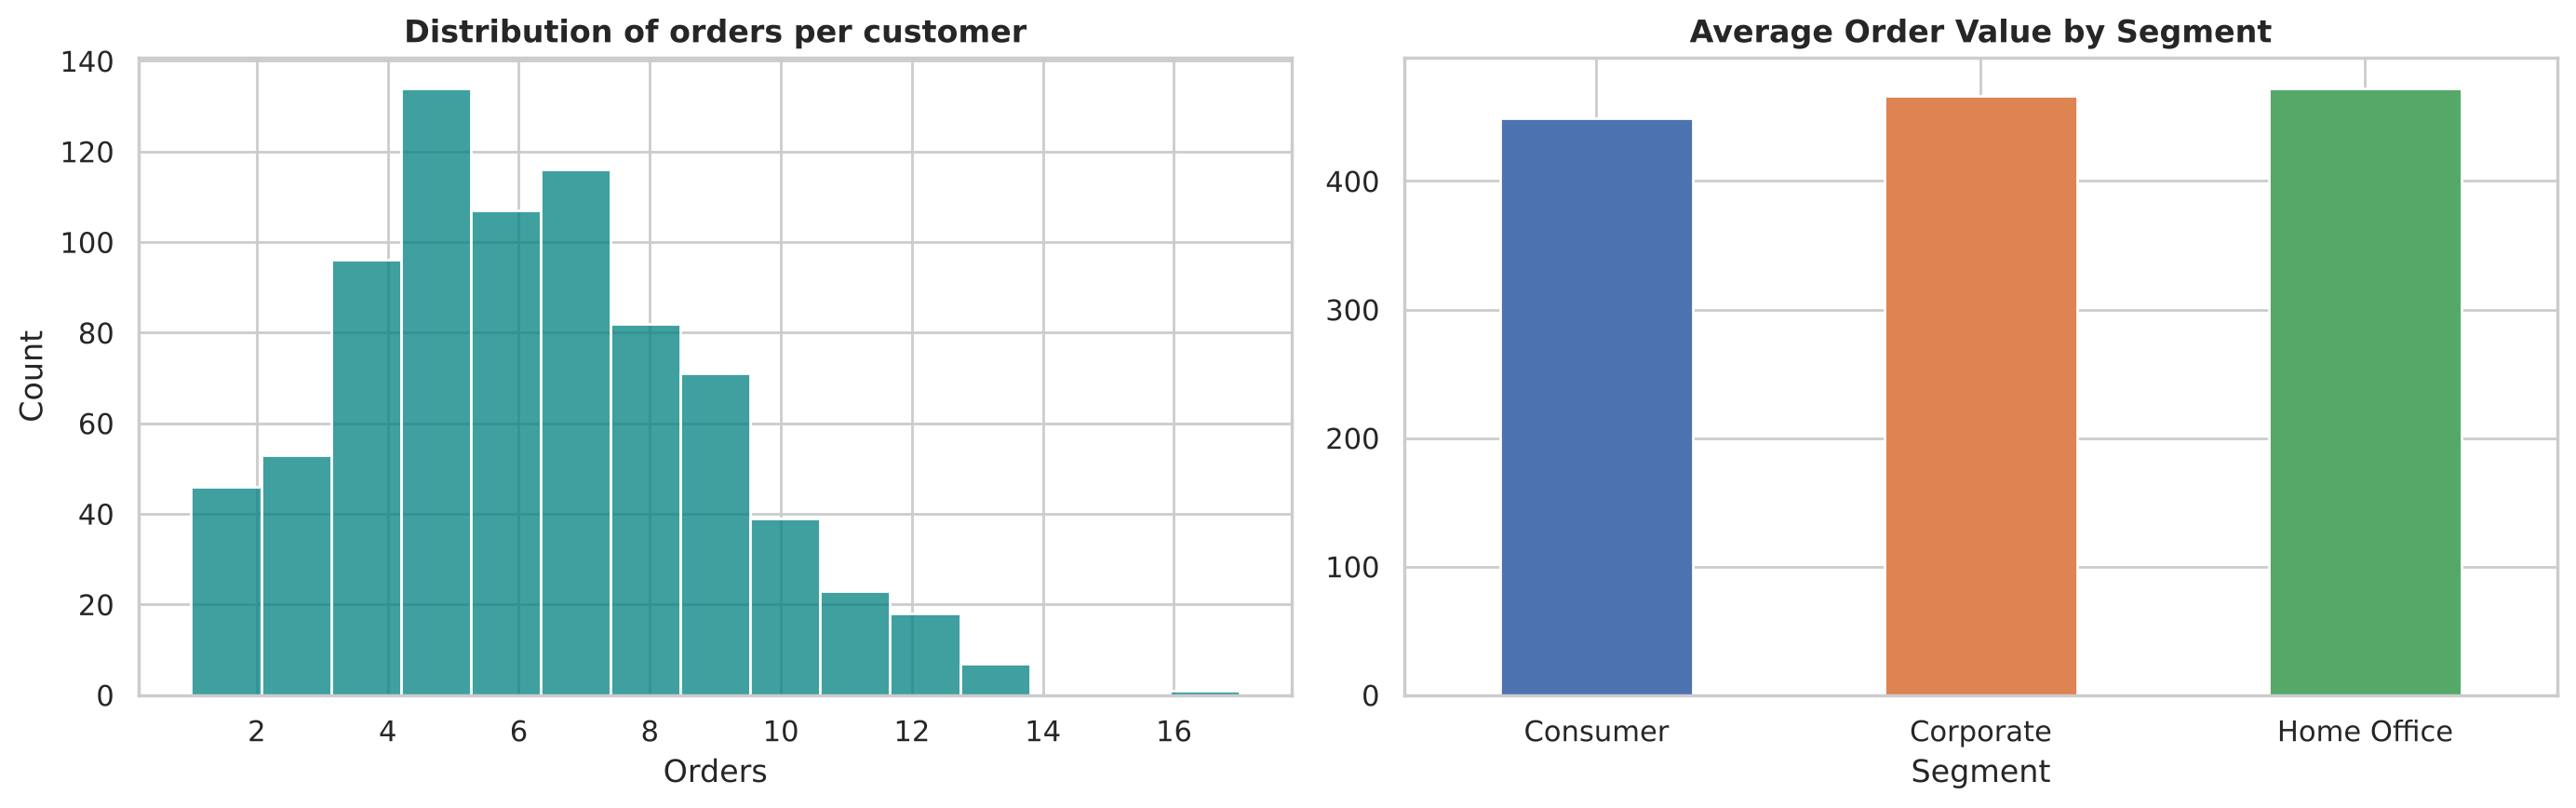

Segment
Consumer      449.11
Corporate     466.41
Home Office   472.36
dtype: float64

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(cust['Orders'], bins=15, ax=ax[0], color='teal')
ax[0].set_title('Distribution of orders per customer')
aov = df.groupby('Segment').apply(lambda x: x['Sales'].sum() / x['Order ID'].nunique())
aov.plot(kind='bar', ax=ax[1], rot=0, color=sns.color_palette()[:3])
ax[1].set_title('Average Order Value by Segment')
plt.tight_layout(); plt.show()
aov

## 5. Monthly Seasonality

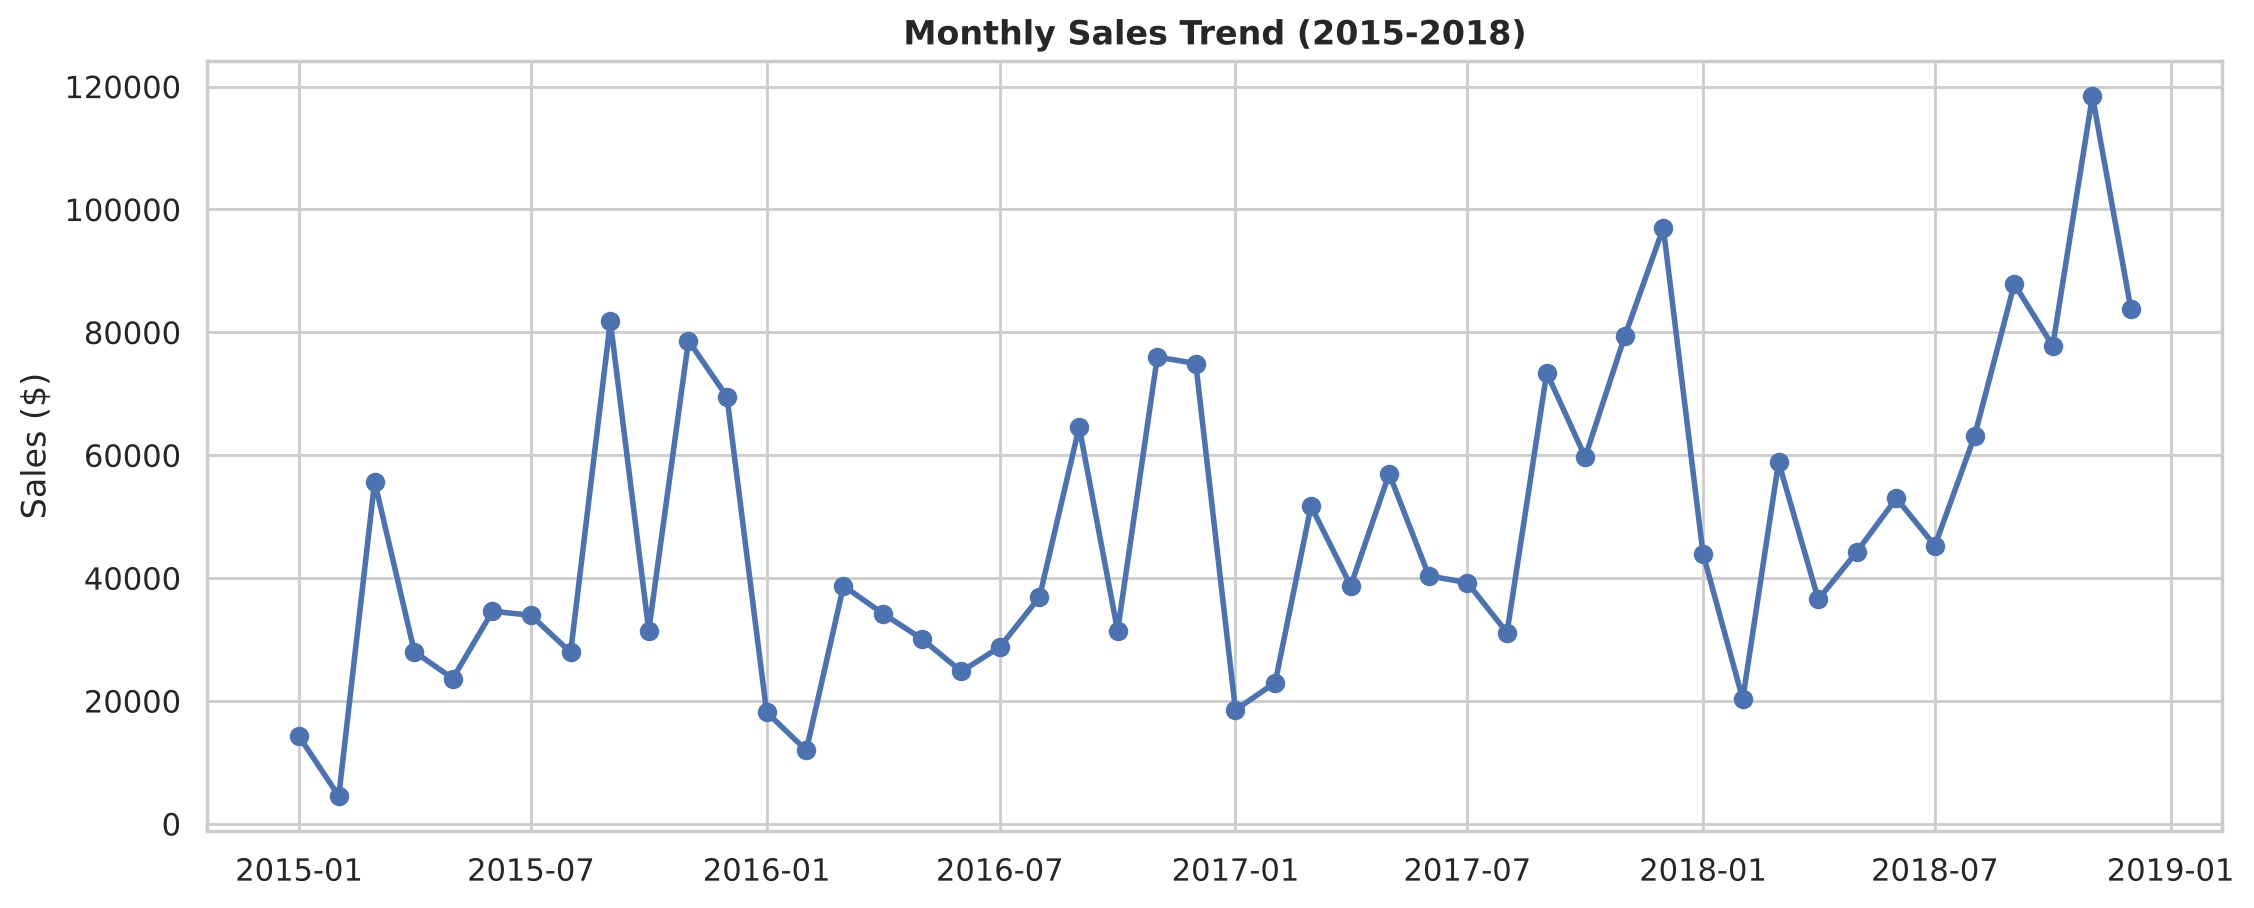

In [25]:
monthly = df.groupby('Year-Month')['Sales'].sum()
monthly.index = monthly.index.to_timestamp()
plt.figure(figsize=(13, 5))
plt.plot(monthly.index, monthly.values, marker='o', linewidth=2)
plt.title('Monthly Sales Trend (2015-2018)')
plt.ylabel('Sales ($)'); plt.show()

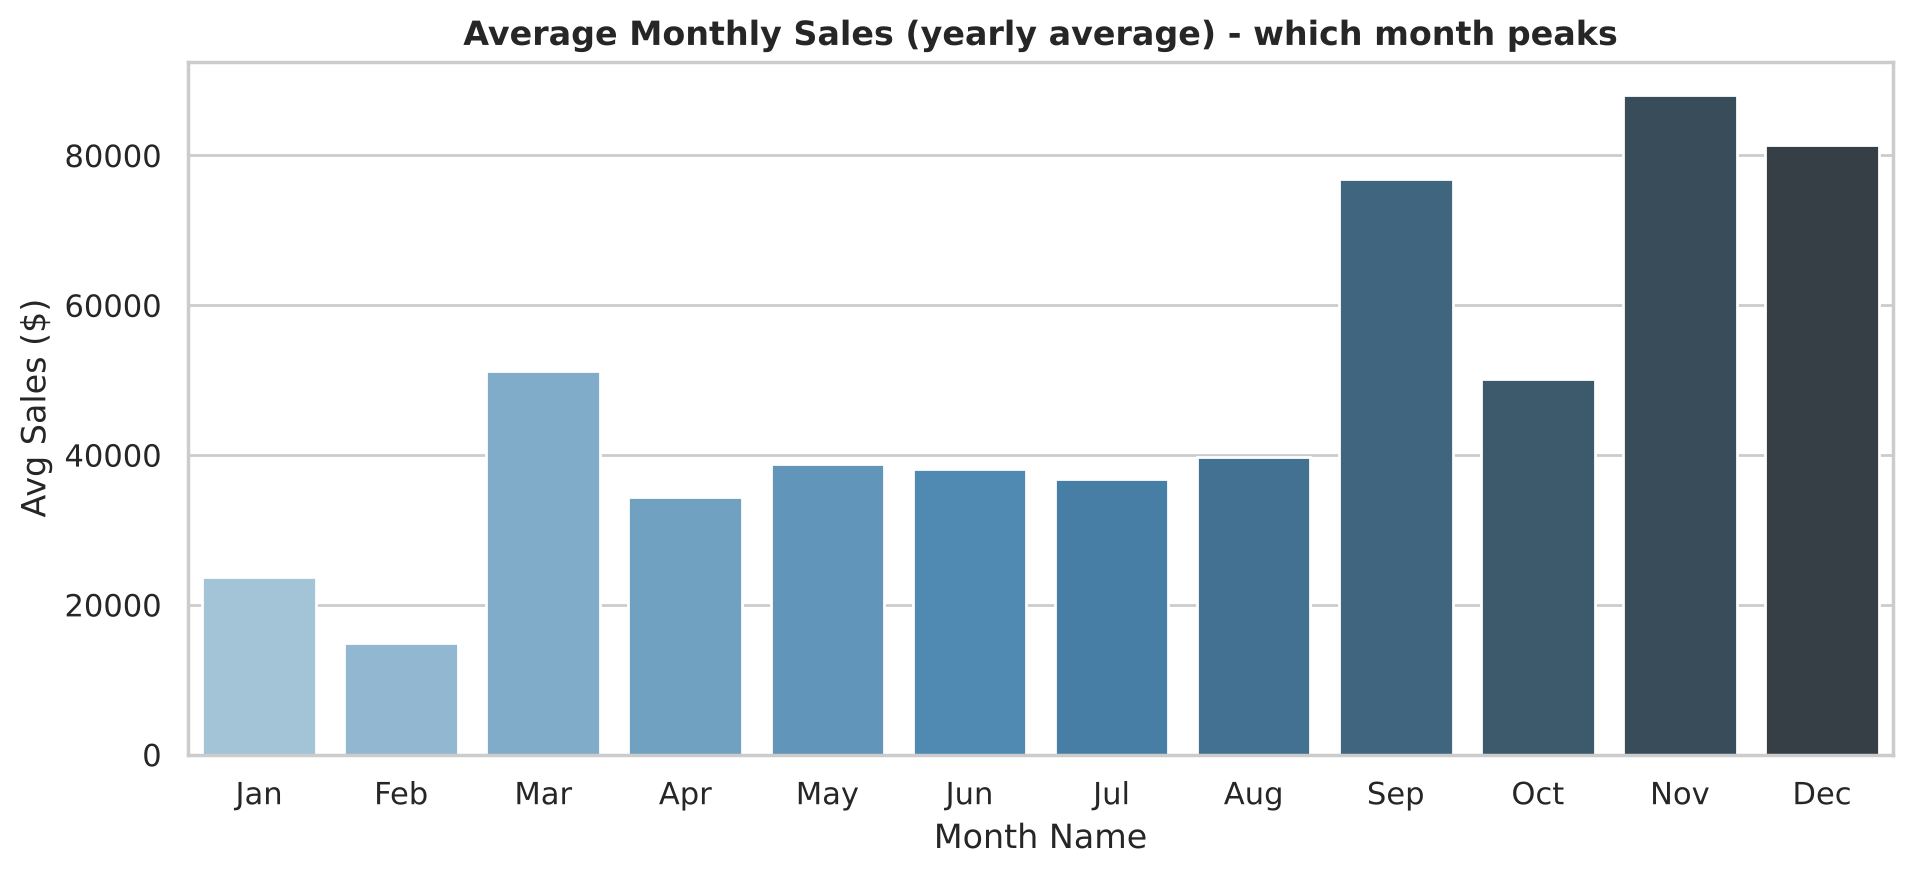

Month Name
Jan   23,731.00
Feb   14,938.00
Mar   51,251.00
Apr   34,370.00
May   38,757.00
Jun   38,180.00
Jul   36,810.00
Aug   39,761.00
Sep   76,912.00
Oct   50,081.00
Nov   88,115.00
Dec   81,323.00
Name: Sales, dtype: float64

In [26]:
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
by_month = df.groupby(['Year', 'Month Name'])['Sales'].sum().groupby('Month Name').mean().reindex(month_order)
plt.figure(figsize=(11, 4.5))
sns.barplot(x=by_month.index, y=by_month.values, palette='Blues_d')
plt.title('Average Monthly Sales (yearly average) - which month peaks'); plt.ylabel('Avg Sales ($)'); plt.show()
by_month.round(0)

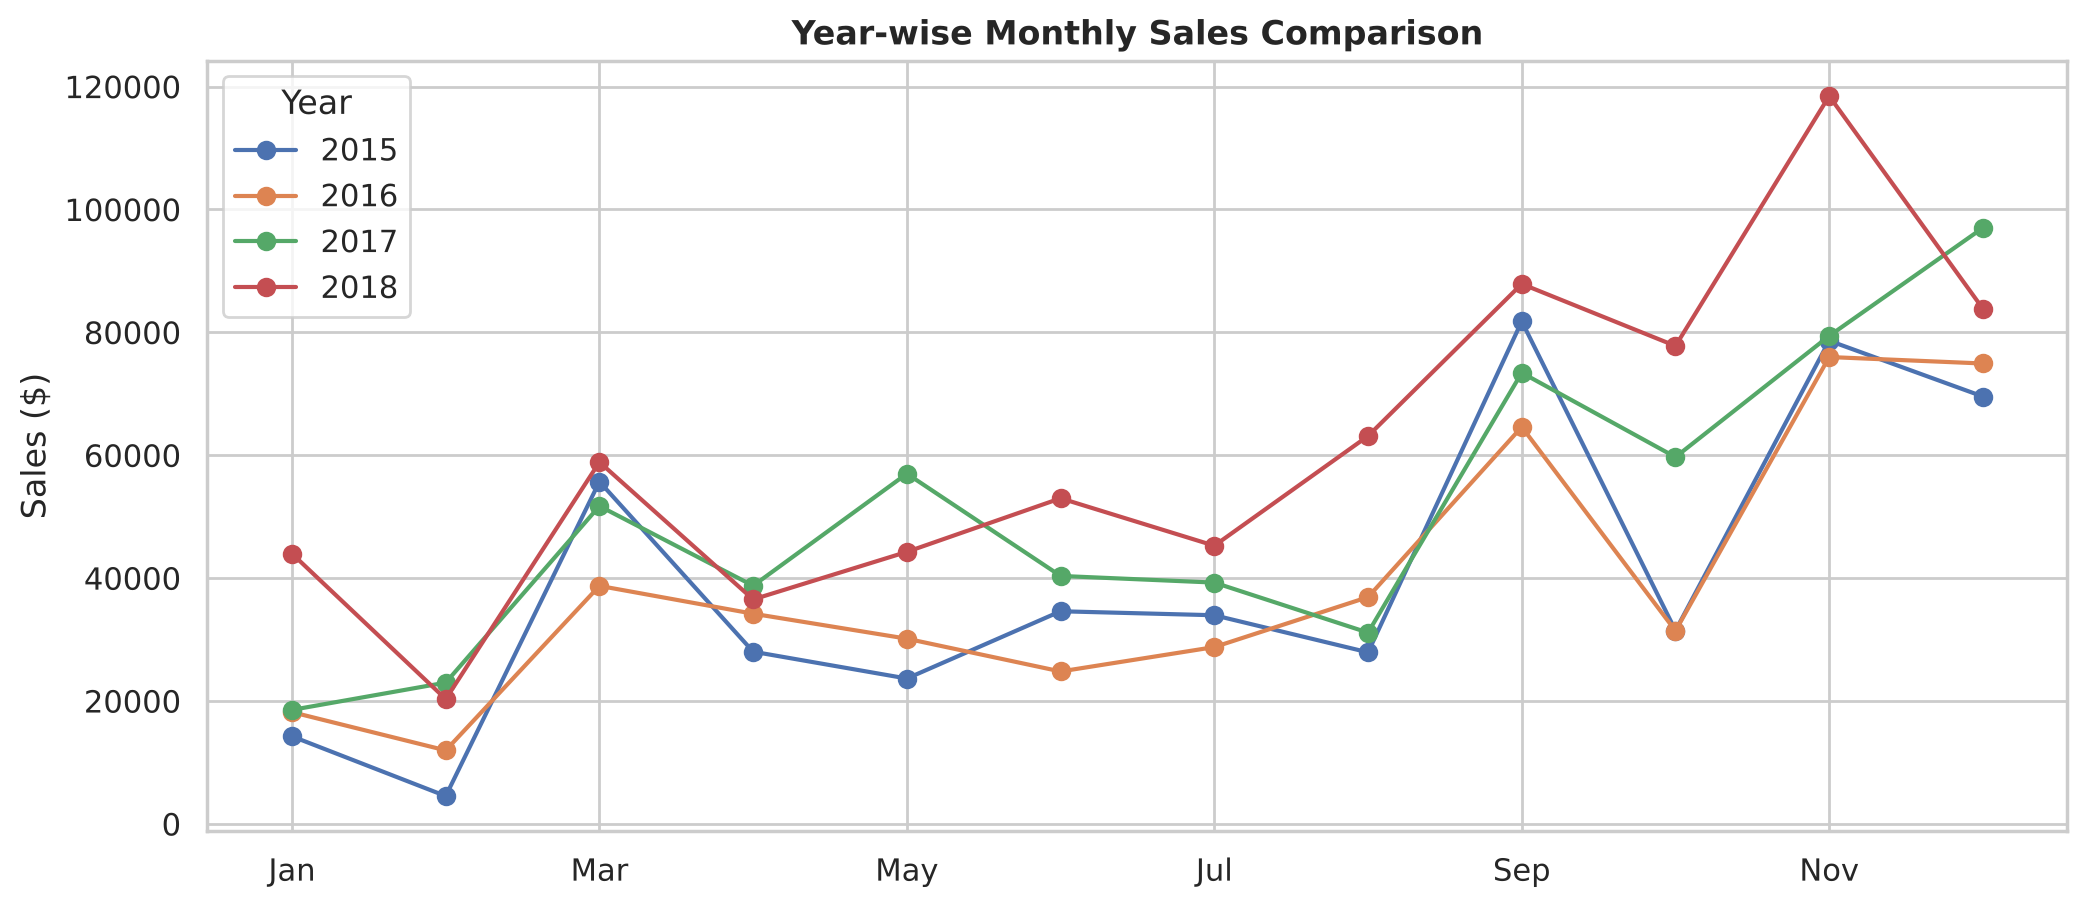

Year
2015   483,966.13
2016   470,532.51
2017   609,205.60
2018   733,215.26
Name: Sales, dtype: float64

In [27]:
yr = df.pivot_table(index='Month', columns='Year', values='Sales', aggfunc='sum')
yr.index = month_order
yr.plot(marker='o', figsize=(12, 5))
plt.title('Year-wise Monthly Sales Comparison'); plt.ylabel('Sales ($)'); plt.show()
df.groupby('Year')['Sales'].sum()

## 6. Category-wise Revenue

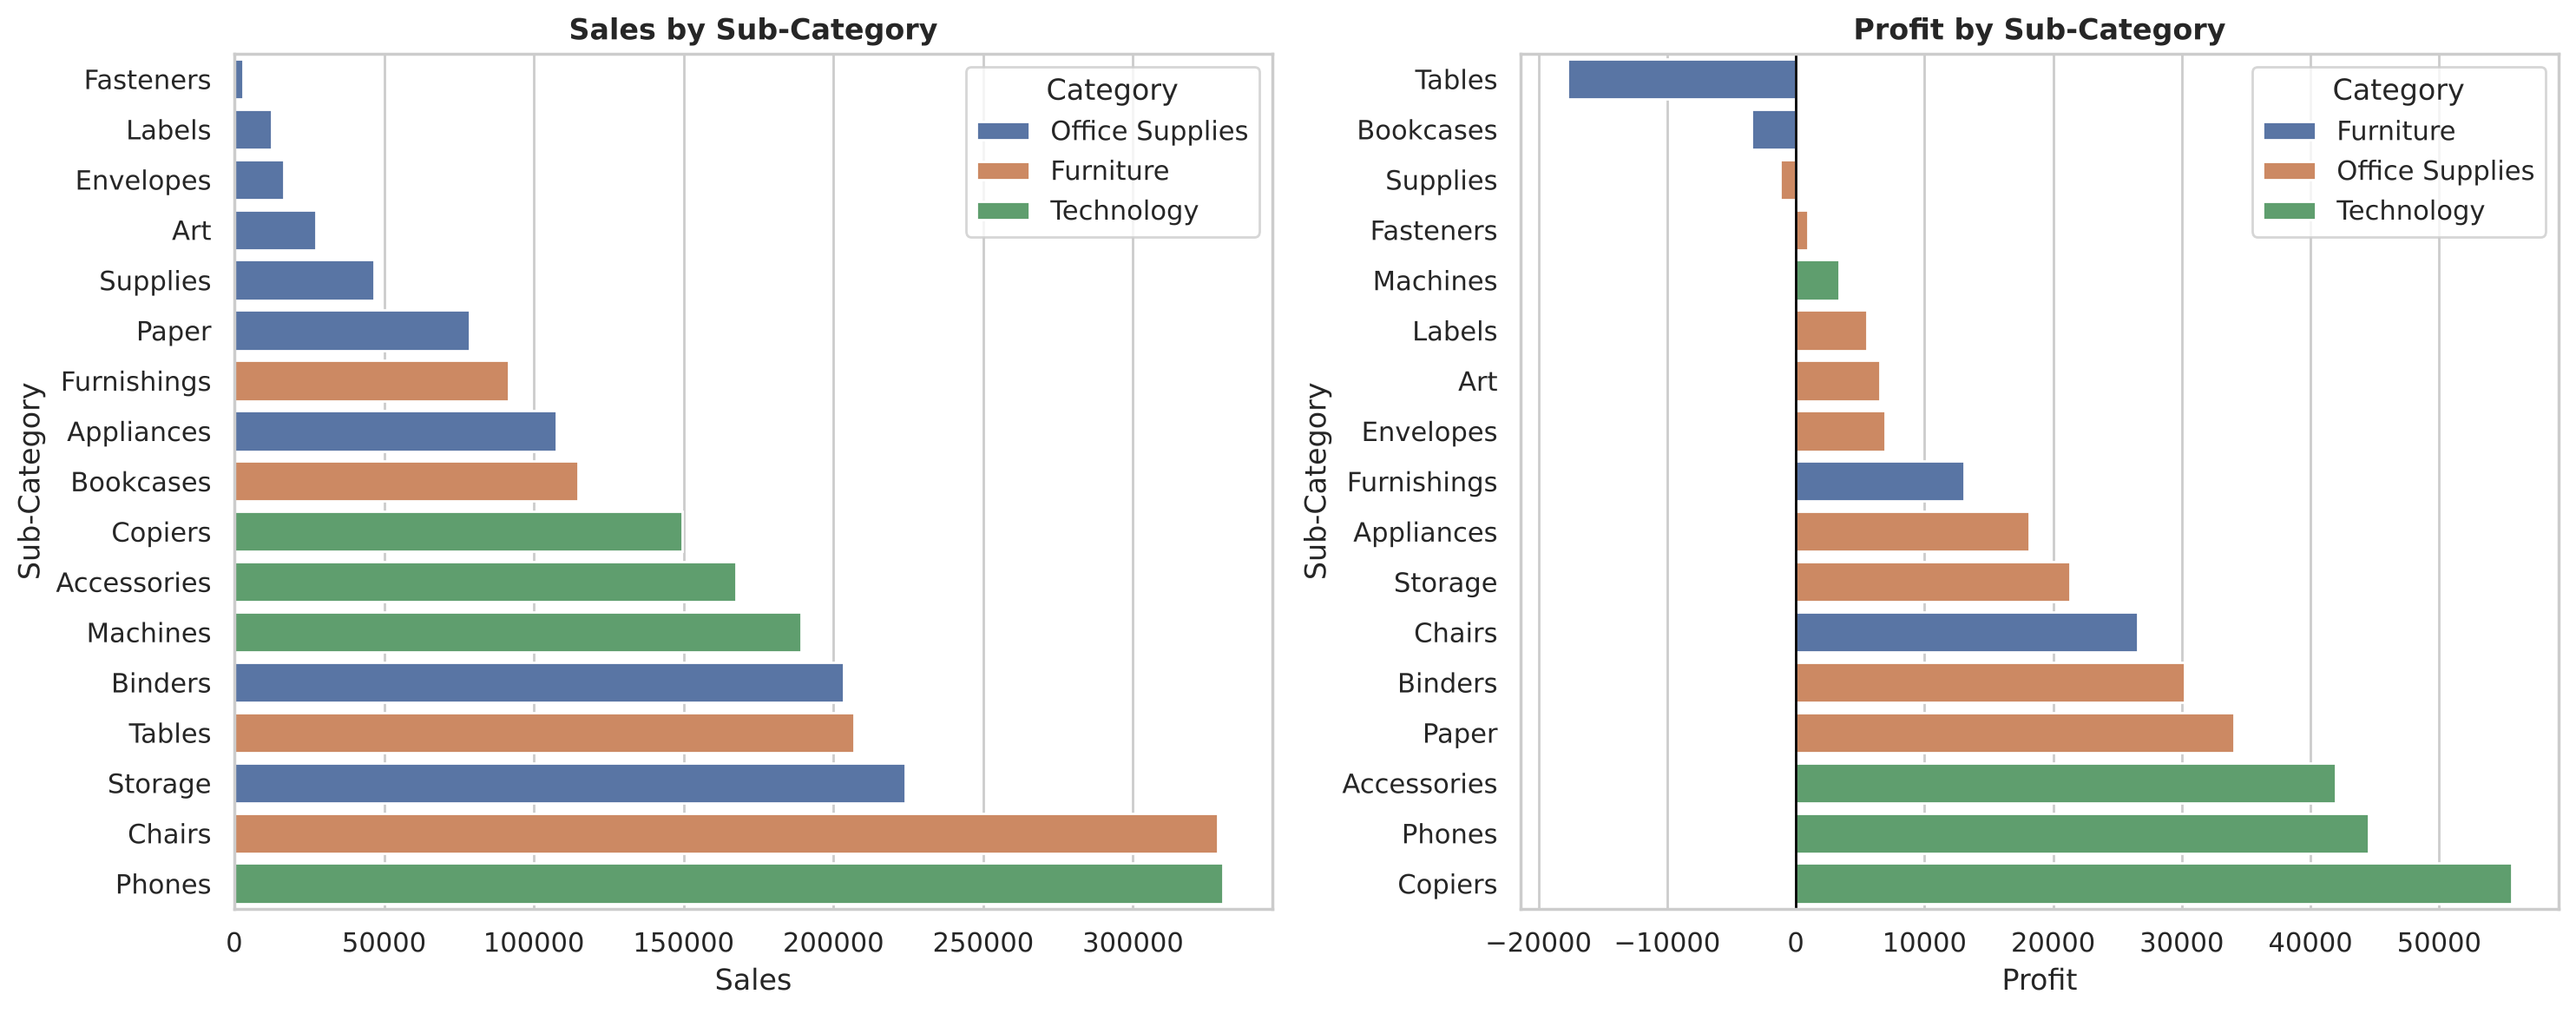

,Category,Sub-Category,Sales,Profit
3,Furniture,Tables,"206,965.53","-17,725.48"
0,Furniture,Bookcases,"114,880.00","-3,472.56"
12,Office Supplies,Supplies,"46,673.54","-1,189.10"
8,Office Supplies,Fasteners,"3,024.28",949.52
15,Technology,Machines,"189,238.63","3,384.76"


In [28]:
sub = df.groupby(['Category', 'Sub-Category'])[['Sales', 'Profit']].sum().reset_index().sort_values('Profit')
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=sub.sort_values('Sales'), y='Sub-Category', x='Sales', hue='Category', dodge=False, ax=ax[0])
ax[0].set_title('Sales by Sub-Category')
sns.barplot(data=sub, y='Sub-Category', x='Profit', hue='Category', dodge=False, ax=ax[1])
ax[1].axvline(0, color='black', linewidth=1); ax[1].set_title('Profit by Sub-Category')
plt.tight_layout(); plt.show()
sub.head(5)

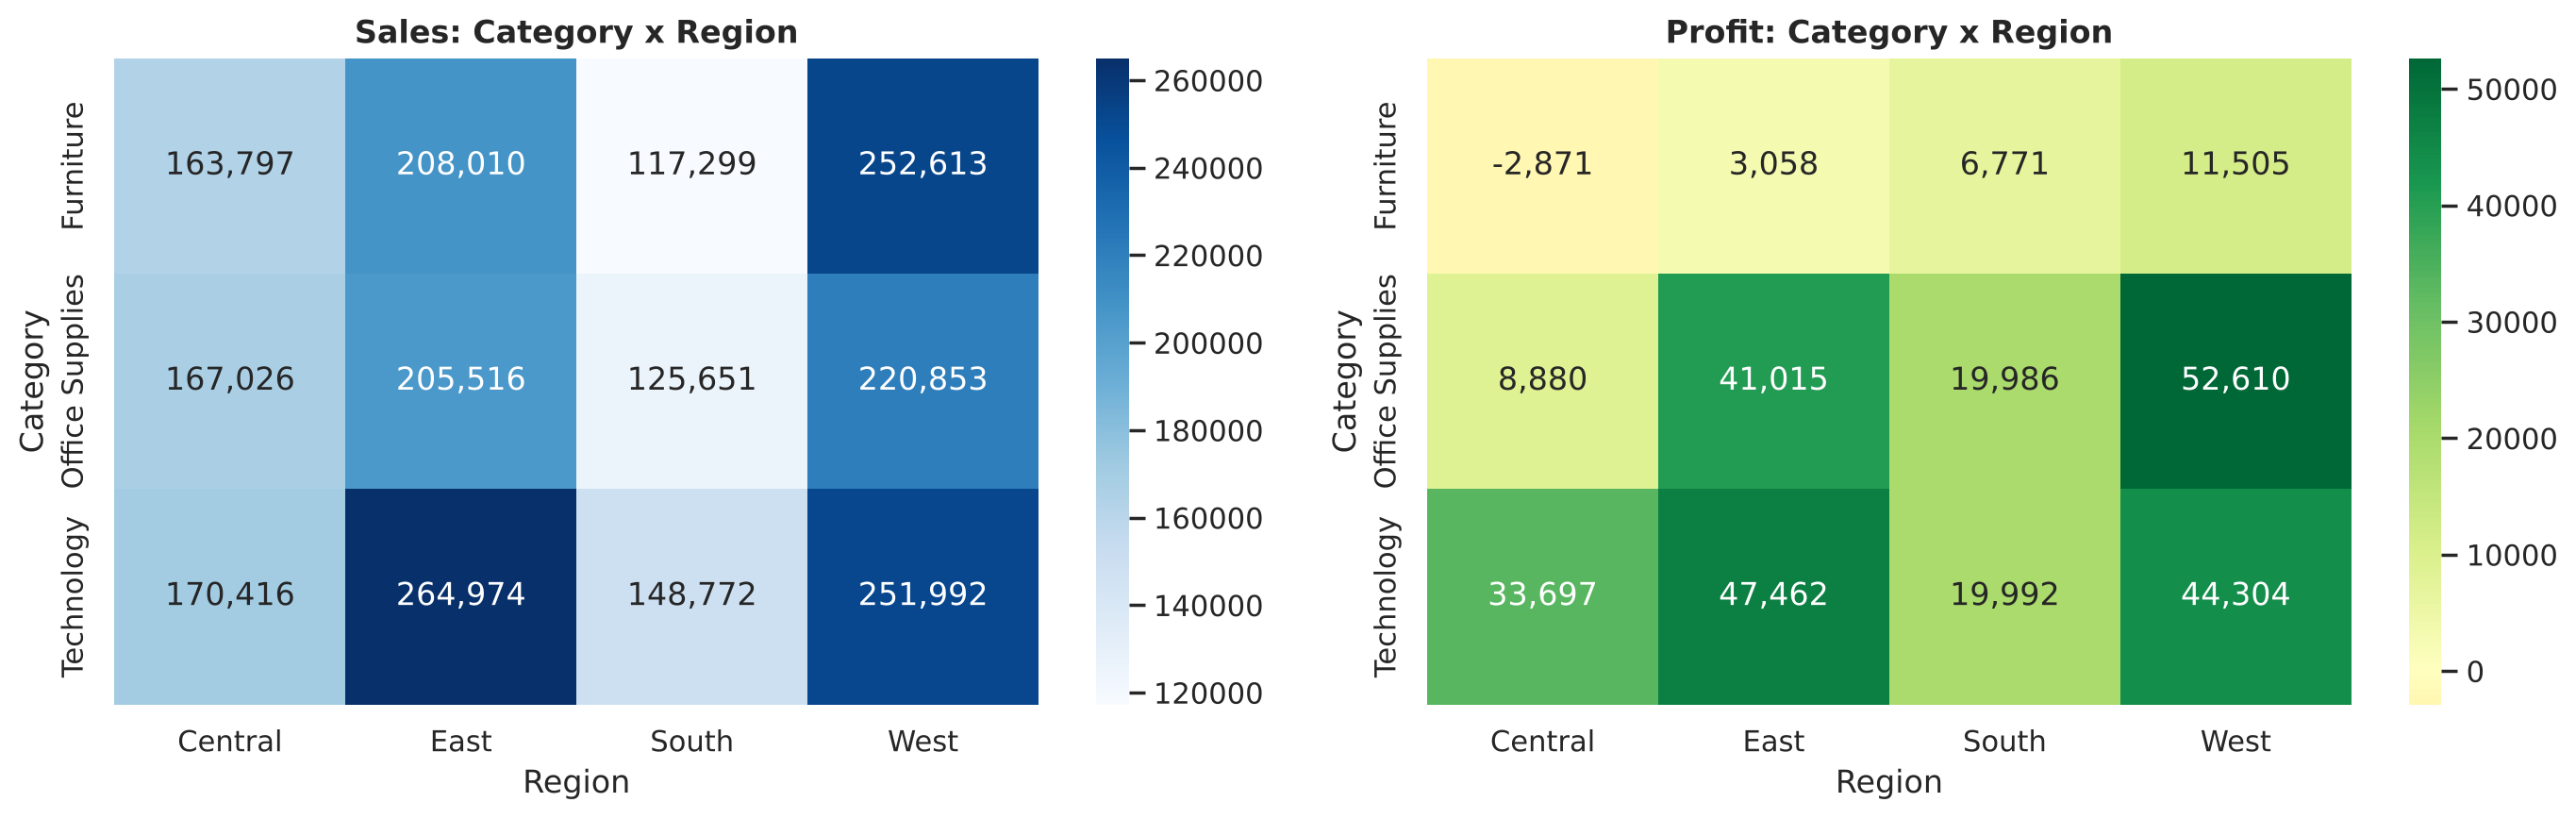

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(df.pivot_table(index='Category', columns='Region', values='Sales', aggfunc='sum'), annot=True, fmt=',.0f', cmap='Blues', ax=ax[0])
ax[0].set_title('Sales: Category x Region')
sns.heatmap(df.pivot_table(index='Category', columns='Region', values='Profit', aggfunc='sum'), annot=True, fmt=',.0f', cmap='RdYlGn', center=0, ax=ax[1])
ax[1].set_title('Profit: Category x Region')
plt.tight_layout(); plt.show()

## 7. Discount Sensitivity

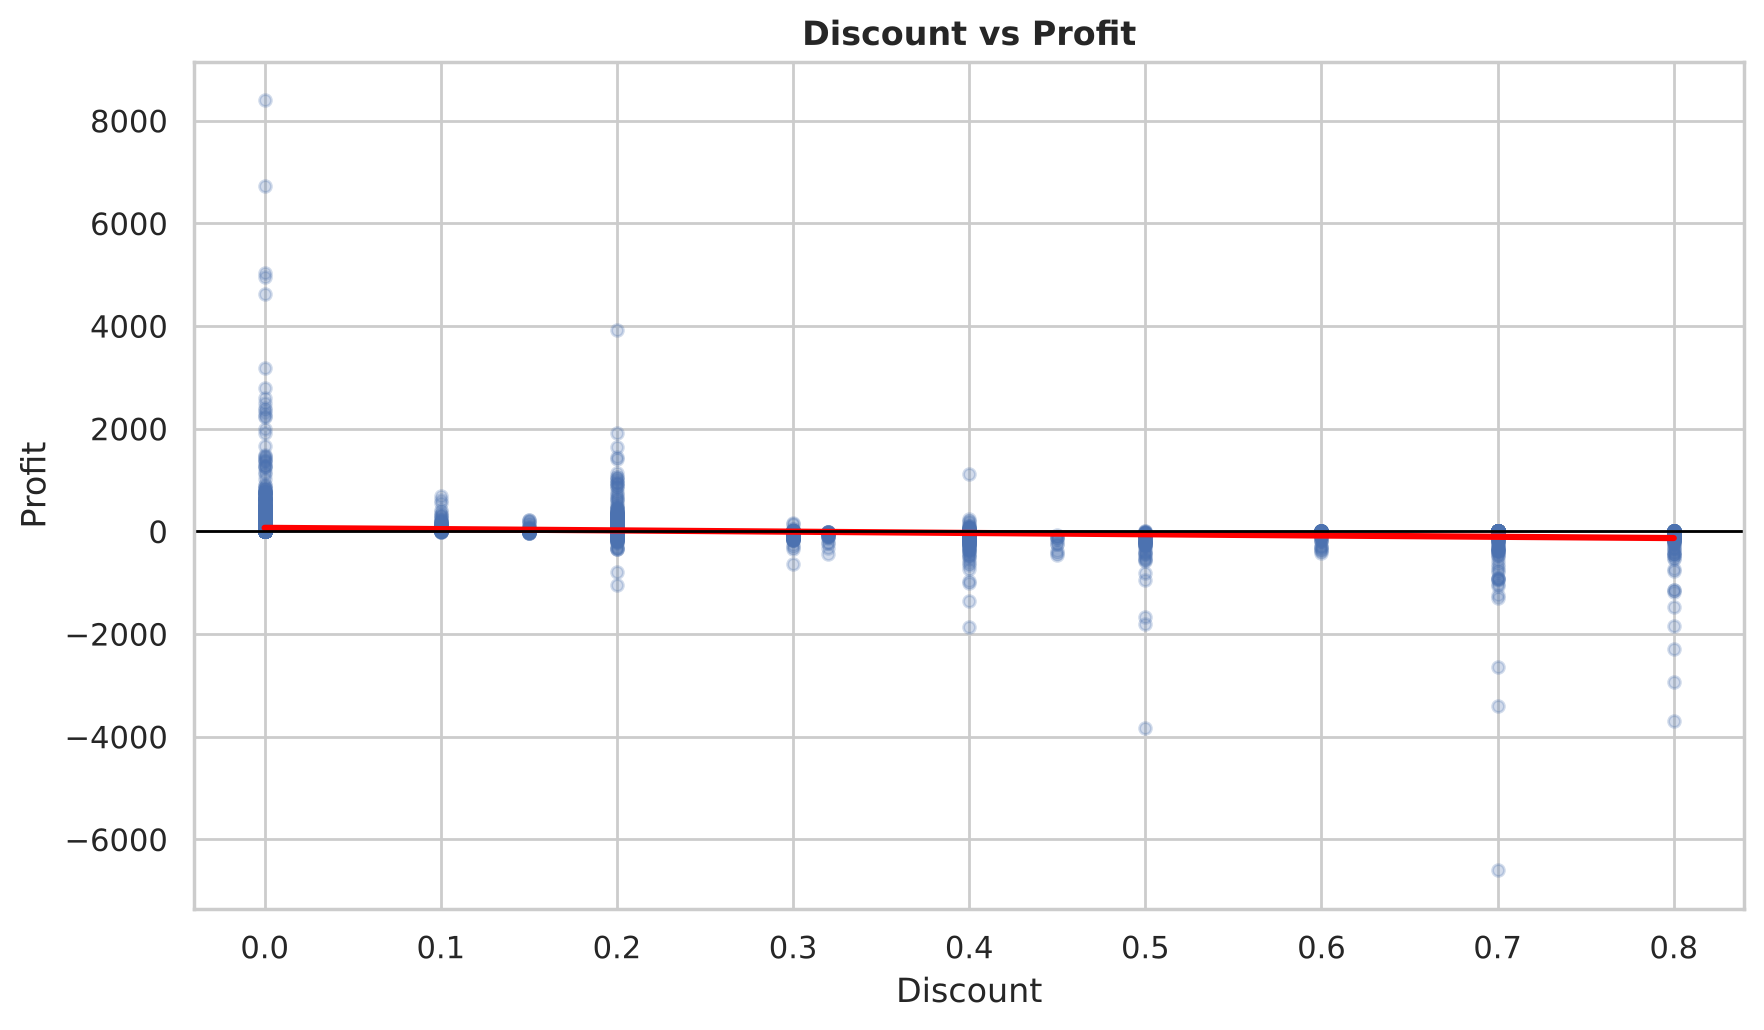

Correlation (Discount, Profit): -0.219


In [30]:
plt.figure(figsize=(10, 5.5))
sns.regplot(data=df, x='Discount', y='Profit', scatter_kws={'alpha': 0.25, 's': 18},
            line_kws={'color': 'red'})
plt.axhline(0, color='black', linewidth=1)
plt.title('Discount vs Profit'); plt.show()
print('Correlation (Discount, Profit):', round(df['Discount'].corr(df['Profit']), 3))

In [31]:
bands = pd.cut(df['Discount'], bins=[-0.01, 0, 0.2, 0.4, 1.0], labels=['0%', '1-20%', '21-40%', '40%+'])
band_tbl = df.groupby(bands, observed=True).agg(Orders=('Profit', 'count'), Avg_Profit=('Profit', 'mean'),
                                                Total_Profit=('Profit', 'sum'), Avg_Margin=('Profit Margin %', 'mean'))
band_tbl

,Orders,Avg_Profit,Total_Profit,Avg_Margin
Discount,,,,
0%,4798,66.90,"320,987.60",34.02
1-20%,3803,26.50,"100,785.47",17.44
21-40%,459,-78.01,"-35,805.41",-16.71
40%+,933,-106.71,"-99,558.59",-108.90


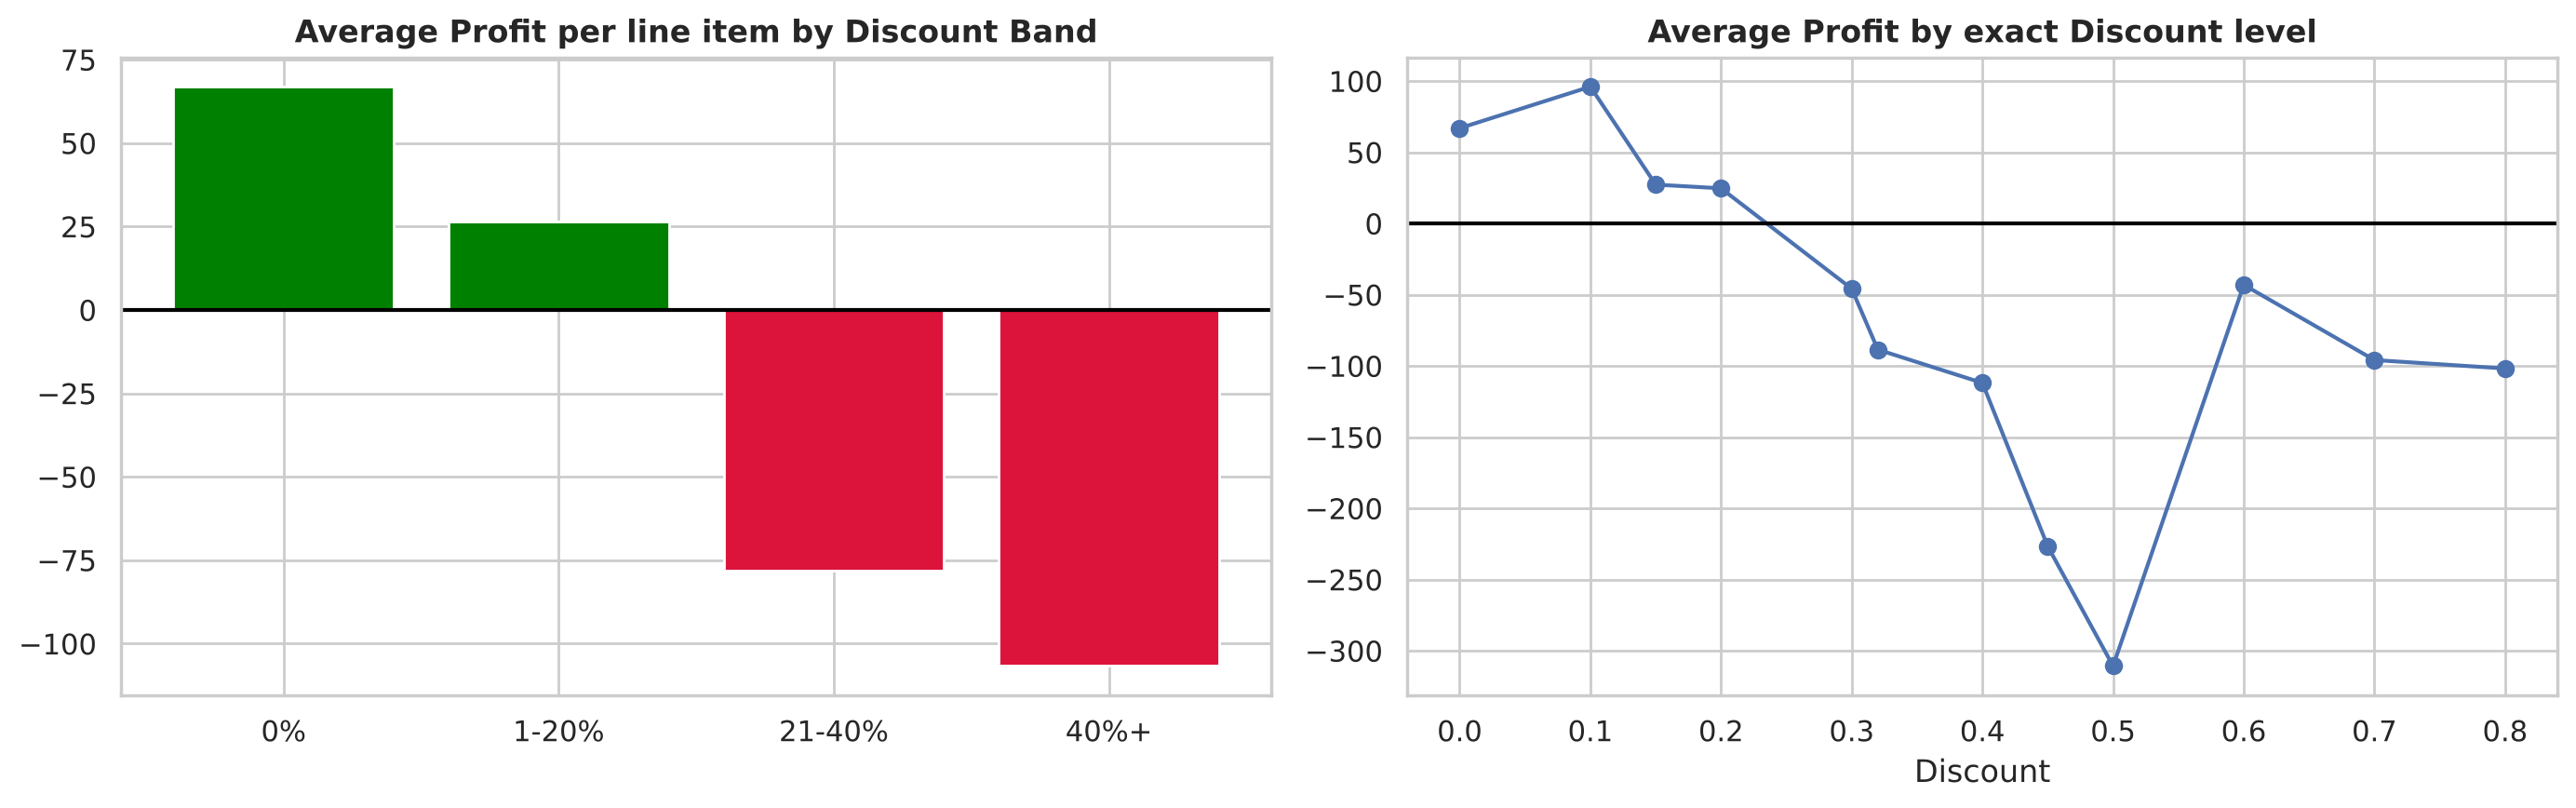

Discount
0.00     66.90
0.10     96.10
0.15     27.30
0.20     24.70
0.30    -45.80
0.32    -88.60
0.40   -111.90
0.45   -226.60
0.50   -310.70
0.60    -43.10
0.70    -95.90
0.80   -101.80
Name: Profit, dtype: float64

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
colors = ['green' if v > 0 else 'crimson' for v in band_tbl['Avg_Profit']]
ax[0].bar(band_tbl.index.astype(str), band_tbl['Avg_Profit'], color=colors)
ax[0].axhline(0, color='black'); ax[0].set_title('Average Profit per line item by Discount Band')
lvl = df.groupby('Discount')['Profit'].mean()
ax[1].plot(lvl.index, lvl.values, marker='o'); ax[1].axhline(0, color='black')
ax[1].set_title('Average Profit by exact Discount level'); ax[1].set_xlabel('Discount')
plt.tight_layout(); plt.show()
lvl.round(1)

In [33]:
loss_start = lvl[lvl < 0].index.min()
print(f'First discount level where average profit turns negative: {loss_start:.0%}')
print(f"Loss-making line item: {(df.Profit < 0).mean()*100:.1f}%")

First discount level where average profit turns negative: 30%
Loss-making line item: 18.7%


## 8. Executive Takeaways

**1. Furniture has sales but almost no profit.**
Furniture sales are $741.7K (about 32% of total) but its margin is only **2.5%**. Office Supplies and Technology both earn a margin of about **17%**. Technology brings the highest revenue ($836K) and profit ($145K). *(See Sections 3 and 6)*
**Recommendation:** Review Furniture pricing and costs, and shift investment toward Technology and Office Supplies.

**2. Tables, Bookcases and Supplies are losing money.**
Tables have $207K in sales but a loss of **$17.7K**; Bookcases lose $3.5K and Supplies lose $1.2K. Copiers earn the most profit ($55.6K). *(See Section 6)*
**Recommendation:** Stop discounting these three sub-categories or negotiate lower supplier costs.

**3. Heavier discounts destroy profit; losses start above 20%.**
Line items with no discount average **$66.9** profit, 1-20% discount averages $26.5, 21-40% averages **-$78**, and 40%+ averages **-$106.7**. The correlation between Discount and Profit is **-0.22**, and average profit turns negative at a 30% discount. *(See Section 7)*
**Recommendation:** Cap discounts at 20% and require approval for anything higher.

**4. Sales show clear seasonality, peaking from September to December.**
November (average about $88K), December and September are the strongest months, while January and February are the weakest. The pattern repeats every year, and yearly sales are growing ($484K in 2015 to $733K in 2018). *(See Section 5)*
**Recommendation:** Increase stock and marketing budget ahead of Q4, and run separate promotions in Q1 (within the discount cap).

**5. West and East are strong, Central is weak. Corporate and Home Office margins beat Consumer.**
West has $725K in sales at a 14.9% margin and East has $678K at 13.5%. Central has $501K in sales but only a **7.9%** margin. Consumer is the largest segment (51% of sales) with an 11.5% margin, while Home Office reaches 14.0%. *(See Sections 3 and 6)*
**Recommendation:** Review discounting and Furniture mix in Central, and focus on retaining Corporate and Home Office customers.

> Customer view: 793 customers placing about 6.3 orders each on average. Average order value is roughly $450-$470 across all three segments.

In [34]:
# Save the cleaned dataset for reuse
out = '../data/superstore_clean.csv' if os.path.isdir('../data') else 'superstore_clean.csv'
df.drop(columns=['Year-Month']).to_csv(out, index=False)
print('Saved cleaned data to', out)

Saved cleaned data to ../data/superstore_clean.csv


## 9. Conclusion
Superstore sales are growing year over year with an overall margin of about **12.5%**. Two large leaks remain: **excessive discounting** and **Furniture (especially Tables and Bookcases)**. Fixing these two could raise profit significantly without needing more sales.